                                              step  discharges  deaths  hospitals  death_rate
0           SPARCS 2022 inpatient discharges (raw)     2103433   59406        NaN    0.028242
1                               With a facility ID     2098043   59339      206.0    0.028283
2   Excluding palliative facility (Calvary, 2 IDs)     2095793   57403      204.0    0.027390
3         Adults 18+, sex F or M (analysis cohort)     1794116   56609      204.0    0.031553
4  Hospitals with >= 100 deaths (main experiments)     1653315   54660      126.0    0.033061


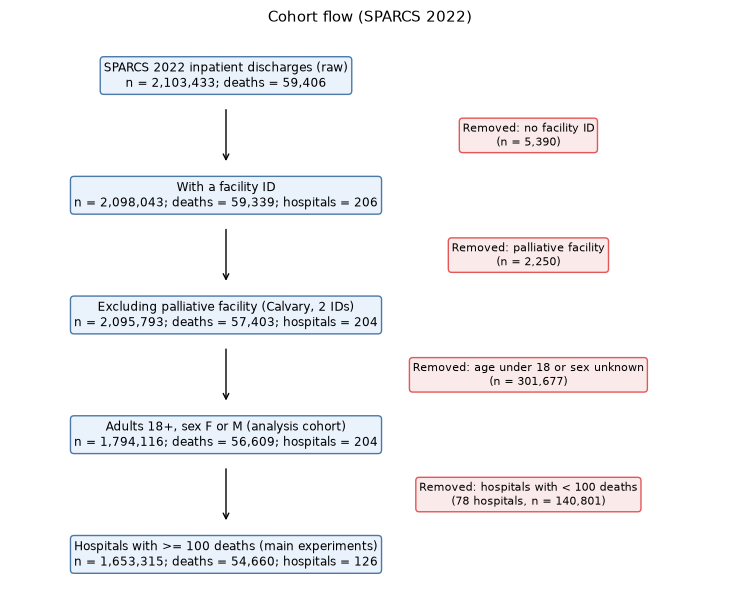

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
os.makedirs("../outputs/figures", exist_ok=True); os.makedirs("../outputs/tables", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
def save(name):
    plt.tight_layout(); plt.savefig(f"../outputs/figures/{name}.png", dpi=300); plt.savefig(f"../outputs/figures/{name}.pdf"); plt.show()

ad = pd.read_parquet("../data/interim/sparcs_2022_adults.parquet").reset_index(drop=True)
hosp = ad.groupby("permanent_facility_id")["y"].agg(n="size", deaths="sum")
hosp["rate"] = hosp.deaths / hosp.n
keep = hosp[hosp.deaths >= 100].index
RAW_N, RAW_D = 2103433, 59406                      # counted on first load (value_counts of patient_disposition)
steps = [("SPARCS 2022 inpatient discharges (raw)", RAW_N, RAW_D, None)]
try:
    cl = pd.read_parquet("../data/interim/sparcs_2022_clean.parquet", columns=["permanent_facility_id", "facility_name", "y"])
    steps.append(("With a facility ID", len(cl), int(cl.y.sum()), cl.permanent_facility_id.nunique()))
    cl2 = cl[~cl.facility_name.str.contains("Calvary", case=False, na=False)]
    steps.append(("Excluding palliative facility (Calvary, 2 IDs)", len(cl2), int(cl2.y.sum()), cl2.permanent_facility_id.nunique()))
except Exception as e:
    print("clean file not found, using counts from the cleaning script output:", e)
    steps += [("With a facility ID", 2098043, None, None), ("Excluding palliative facility (Calvary, 2 IDs)", 2095793, None, None)]
steps.append(("Adults 18+, sex F or M (analysis cohort)", len(ad), int(ad.y.sum()), ad.permanent_facility_id.nunique()))
sub = ad[ad.permanent_facility_id.isin(keep)]
steps.append(("Hospitals with >= 100 deaths (main experiments)", len(sub), int(sub.y.sum()), len(keep)))
T1 = pd.DataFrame(steps, columns=["step", "discharges", "deaths", "hospitals"])
T1["death_rate"] = T1.deaths / T1.discharges
T1.to_csv("../outputs/tables/T1_cohort.csv", index=False)
print(T1.to_string())

fig, ax = plt.subplots(figsize=(7.5, 6.2)); ax.axis("off")
labels = [f"{r.step}\nn = {r.discharges:,}" + (f"; deaths = {int(r.deaths):,}" if pd.notna(r.deaths) else "") +
          (f"; hospitals = {int(r.hospitals)}" if pd.notna(r.hospitals) else "") for r in T1.itertuples()]
removed = [None, f"Removed: no facility ID\n(n = {RAW_N - T1.discharges[1]:,})", f"Removed: palliative facility\n(n = {T1.discharges[1] - T1.discharges[2]:,})",
           f"Removed: age under 18 or sex unknown\n(n = {T1.discharges[2] - T1.discharges[3]:,})", f"Removed: hospitals with < 100 deaths\n({len(hosp) - len(keep)} hospitals, n = {T1.discharges[3] - T1.discharges[4]:,})"]
ys = np.linspace(0.92, 0.08, len(labels))
for i, (lab, y_) in enumerate(zip(labels, ys)):
    ax.text(0.3, y_, lab, ha="center", va="center", fontsize=8.5, bbox=dict(boxstyle="round", fc="#eaf2fb", ec="#4C78A8"))
    if i > 0:
        ax.annotate("", xy=(0.3, y_ + 0.055), xytext=(0.3, ys[i - 1] - 0.055), arrowprops=dict(arrowstyle="->"))
        ax.text(0.72, (y_ + ys[i - 1]) / 2, removed[i], ha="center", va="center", fontsize=8, bbox=dict(boxstyle="round", fc="#fbeaea", ec="#E45756"))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_title("Cohort flow (SPARCS 2022)", fontsize=11)
save("fig2_cohort_flow")

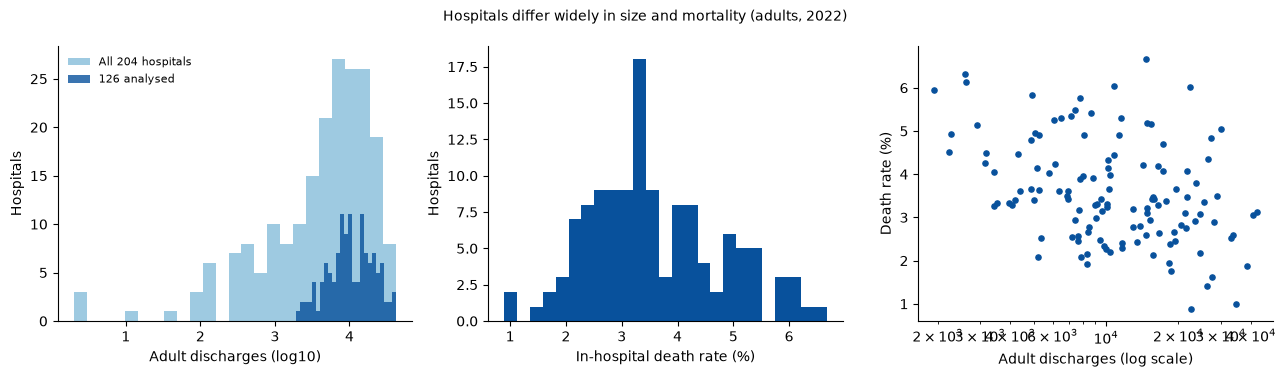

               n    deaths     rate
count    126.000   126.000  126.000
mean   13121.548   433.810    0.036
std     8863.272   296.935    0.012
min     1934.000   100.000    0.009
25%     6881.500   227.250    0.027
50%    10191.000   344.000    0.034
75%    17582.250   551.750    0.043
max    42353.000  1521.000    0.067


In [2]:
hh = hosp.loc[keep]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].hist(np.log10(hosp.n), bins=25, color="#9ecae1", label="All 204 hospitals"); ax[0].hist(np.log10(hh.n), bins=25, color="#08519c", alpha=0.8, label="126 analysed")
ax[0].set_xlabel("Adult discharges (log10)"); ax[0].set_ylabel("Hospitals"); ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(100 * hh.rate, bins=25, color="#08519c"); ax[1].set_xlabel("In-hospital death rate (%)"); ax[1].set_ylabel("Hospitals")
ax[2].scatter(hh.n, 100 * hh.rate, s=14, c="#08519c"); ax[2].set_xscale("log")
ax[2].set_xlabel("Adult discharges (log scale)"); ax[2].set_ylabel("Death rate (%)")
fig.suptitle("Hospitals differ widely in size and mortality (adults, 2022)", fontsize=10)
save("fig3_heterogeneity")
print(hh[["n", "deaths", "rate"]].describe().round(3))

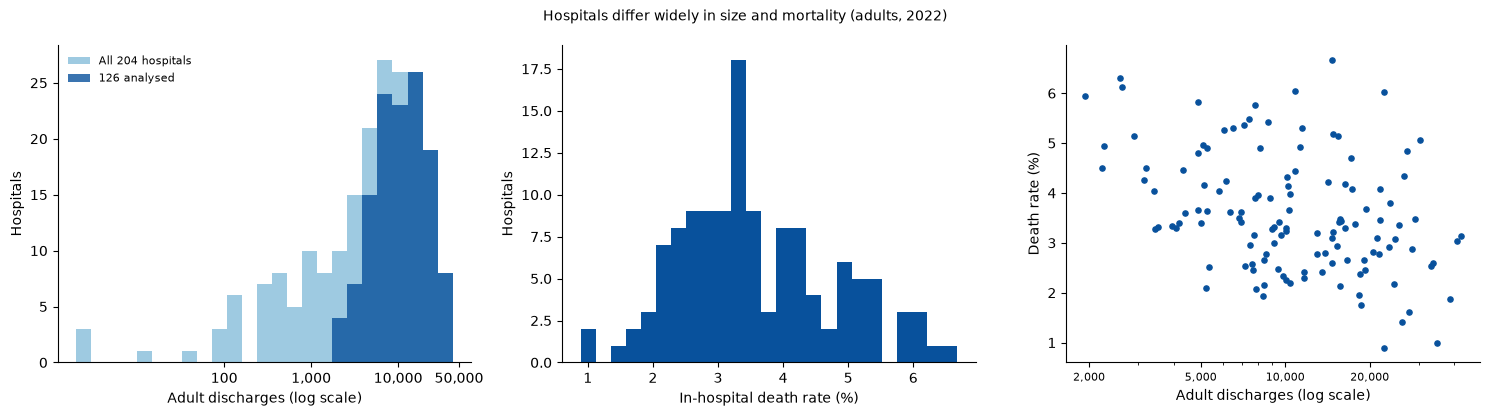

               n    deaths     rate
count    126.000   126.000  126.000
mean   13121.548   433.810    0.036
std     8863.272   296.935    0.012
min     1934.000   100.000    0.009
25%     6881.500   227.250    0.027
50%    10191.000   344.000    0.034
75%    17582.250   551.750    0.043
max    42353.000  1521.000    0.067


In [3]:
from matplotlib.ticker import FixedLocator, FixedFormatter, NullFormatter, FuncFormatter

hh = hosp.loc[keep]
ticks = [2000, 5000, 10000, 20000, 50000]

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

# panel 1: hospital size distribution (log10 axis shown as real numbers)
bins = np.linspace(np.log10(hosp.n.min()), np.log10(hosp.n.max()), 26)
ax[0].hist(np.log10(hosp.n), bins=bins, color="#9ecae1", label="All 204 hospitals")
ax[0].hist(np.log10(hh.n), bins=bins, color="#08519c", alpha=0.8, label="126 analysed")
lt = [2, 3, 4, 4.7]
ax[0].xaxis.set_major_locator(FixedLocator(lt))
ax[0].xaxis.set_major_formatter(FixedFormatter(["100", "1,000", "10,000", "50,000"]))
ax[0].set_xlabel("Adult discharges (log scale)"); ax[0].set_ylabel("Hospitals")
ax[0].legend(frameon=False, fontsize=8)

# panel 2: death rate
ax[1].hist(100 * hh.rate, bins=25, color="#08519c")
ax[1].set_xlabel("In-hospital death rate (%)"); ax[1].set_ylabel("Hospitals")

# panel 3: size against death rate, log axis with plain labels and no minor labels
ax[2].scatter(hh.n, 100 * hh.rate, s=14, c="#08519c")
ax[2].set_xscale("log")
ax[2].xaxis.set_major_locator(FixedLocator(ticks))
ax[2].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
ax[2].xaxis.set_minor_formatter(NullFormatter())
ax[2].tick_params(axis="x", labelsize=8, rotation=0)
ax[2].set_xlabel("Adult discharges (log scale)"); ax[2].set_ylabel("Death rate (%)")

fig.suptitle("Hospitals differ widely in size and mortality (adults, 2022)", fontsize=10)
plt.subplots_adjust(wspace=0.3)
save("fig3_heterogeneity")
print(hh[["n", "deaths", "rate"]].describe().round(3))

In [4]:
sub = ad[ad.permanent_facility_id.isin(keep)].copy()
sub["old"] = (sub.age_group == "70 or Older").astype(int); sub["white"] = (sub.race == "White").astype(int)
sub["black"] = (sub.race == "Black/African American").astype(int); sub["emerg"] = (sub.type_of_admission == "Emergency").astype(int)
sub["female"] = (sub.gender == "F").astype(int)
ph = sub.groupby("permanent_facility_id").agg(n=("y", "size"), deaths=("y", "sum"), rate=("y", "mean"), old=("old", "mean"),
                                              white=("white", "mean"), black=("black", "mean"), emerg=("emerg", "mean"), female=("female", "mean"))
ph["size_quartile"] = pd.qcut(ph.n, 4, labels=["Smallest", "Q2", "Q3", "Largest"])
T2 = ph.groupby("size_quartile", observed=True).agg(hospitals=("n", "size"), median_discharges=("n", "median"), median_deaths=("deaths", "median"),
        median_death_rate=("rate", "median"), mean_pct_70plus=("old", "mean"), mean_pct_white=("white", "mean"), mean_pct_black=("black", "mean"),
        mean_pct_emergency=("emerg", "mean"), mean_pct_female=("female", "mean"))
for c in [c for c in T2.columns if c.startswith("mean_pct")]:
    T2[c] = 100 * T2[c]
T2.round(2).to_csv("../outputs/tables/T2_hospital_characteristics.csv")
print(T2.round(2).to_string())

T3 = pd.DataFrame([
    ("Outcome", "y", "patient_disposition equals Expired (in-hospital death)", "binary"),
    ("Feature", "age_group", "0-17 excluded; 18-29, 30-49, 50-69, 70+", "categorical"),
    ("Feature", "gender", "F or M (unknown excluded)", "categorical"),
    ("Feature", "race", "White, Black/African American, Other Race, Multi-racial", "categorical"),
    ("Feature", "ethnicity", "Spanish/Hispanic, Not Span/Hispanic, Multi-ethnic, Unknown", "categorical"),
    ("Feature", "type_of_admission", "Emergency, Elective, Urgent, Newborn, Trauma, Not Available", "categorical"),
    ("Feature", "emergency_department_indicator", "Y or N", "binary"),
    ("Feature", "payment_typology_1", "Primary payer category", "categorical"),
    ("Feature", "dx_sys", "First 3 characters of the CCSR principal diagnosis code (body system)", "categorical"),
    ("Sensitivity only", "apr_severity_of_illness_code, apr_risk_of_mortality", "Grouper outputs; used only in the with-APR sensitivity run", "ordinal"),
    ("Excluded", "length_of_stay, total_charges, total_costs", "Depend on the outcome; never used", "numeric"),
    ("Group (certification)", "gender; age_band (18-49, 50-69, 70+); race_grp (White, Black/African American, Other/Multi-racial)", "Fixed before certification data were seen; tested when >= 20 training deaths in the hospital", "categorical"),
    ("Group (descriptive only)", "race_grp x age_band", "Not used in certification", "categorical")],
    columns=["role", "variable", "definition", "type"])
T3.to_csv("../outputs/tables/T3_features.csv", index=False)
print(T3.to_string())

               hospitals  median_discharges  median_deaths  median_death_rate  mean_pct_70plus  mean_pct_white  mean_pct_black  mean_pct_emergency  mean_pct_female
size_quartile                                                                                                                                                      
Smallest              32             4633.0          162.0               0.04            42.94           79.53           11.38               75.01            56.20
Q2                    31             8370.0          272.0               0.03            38.78           58.77           19.21               82.60            55.66
Q3                    31            14643.0          477.0               0.03            32.97           48.48           24.32               78.95            55.04
Largest               32            24051.5          719.0               0.03            36.45           52.95           17.02               69.87            56.39
                

In [5]:
rows = []
for cut in [50, 100, 200]:
    rows.append(("hospitals with at least %d deaths" % cut, int((hosp.deaths >= cut).sum()), "", ""))
parts = []
for var in ["gender", "age_band", "race_grp"]:
    t = ad.groupby(["permanent_facility_id", var])["y"].agg(n="size", deaths="sum").reset_index(); t["var"] = var; parts.append(t)
gr = pd.concat(parts); gr["cert_deaths"] = gr.deaths * 0.25
for var in ["gender", "age_band", "race_grp"]:
    t = gr[gr["var"] == var]
    rows.append((f"{var}: hospital-group cells with expected certification deaths >= 10 / 20 / 40", len(t),
                 " / ".join(f"{(t.cert_deaths >= th).sum()}" for th in (10, 20, 40)),
                 " / ".join(f"{100 * (t.cert_deaths >= th).mean():.0f}%" for th in (10, 20, 40))))
T5 = pd.DataFrame(rows, columns=["item", "total", "count", "share"])
T5.to_csv("../outputs/tables/T5_power.csv", index=False)
print(T5.to_string())

                                                                                item  total            count            share
0                                                  hospitals with at least 50 deaths    142                                  
1                                                 hospitals with at least 100 deaths    126                                  
2                                                 hospitals with at least 200 deaths     99                                  
3    gender: hospital-group cells with expected certification deaths >= 10 / 20 / 40    404  266 / 218 / 139  66% / 54% / 34%
4  age_band: hospital-group cells with expected certification deaths >= 10 / 20 / 40    600  277 / 202 / 121  46% / 34% / 20%
5  race_grp: hospital-group cells with expected certification deaths >= 10 / 20 / 40    585  272 / 206 / 120  46% / 35% / 21%
